<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# One package release, several different wheel files

For pandas 2.2.3, which files were published for an ordinary CPython interpreter/ABI pair, and how much do their declared download sizes vary by platform? Start with live PyPI artifact metadata, separate wheel filename tags in SQL, then compare counts and sizes. The filename is an inventory key, not proof that a file can run on this machine.

**Live public metadata, no replay.** The worker reads the exact pandas release from PyPI; it does not download or install package files. Per-row `observed_at` values record retrieval time, not the release upload time. Public metadata, yanking status and availability can change even for a fixed release.

## Select the interpreter and ABI

`CPYTHON_TAG` accepts **cp39, cp310, cp311, cp312 or cp313**, default **cp313**. We require that value in **both** the Python and ABI filename fields, leaving free-threaded ABI tags and other interpreters outside this selection. The experiment uses **cp312**. Restart and run all after editing. OS, architecture and system-library compatibility remain additional requirements.

In [1]:
CPYTHON_TAG = "cp313"

In [2]:
from datetime import datetime, timezone
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from notebook_support import PublicSources, finish, theme

STARTED_UTC = datetime.now(timezone.utc).isoformat(timespec="seconds")
public = PublicSources()
theme()
notebook_secret_directory = TemporaryDirectory(prefix="vgi-notebook-secrets-")
connection = haybarn.connect(
    config={"secret_directory": notebook_secret_directory.name, "allow_persistent_secrets": False}
)
assert connection.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [], (
    "Public example must start without SQL secrets"
)
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection
assert CPYTHON_TAG in {"cp39", "cp310", "cp311", "cp312", "cp313"}

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-software-packages/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-software-packages/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-software-packages/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-software-packages/notebooks/pyproject.toml.

## Launch the published package worker

The literal release location selects the package-worker executable from v0.2.0. The helper supplies only anonymous public endpoints and a fresh disposable metadata cache. No root checkout, local Bun build or private registry credentials are used.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'packages' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-software-packages@v0.2.0/vgi-packages-worker');
SELECT source_id,operation,supported FROM packages.main.capabilities
WHERE source_id='pypi_public' AND operation='artifacts';

,source_id,operation,supported
0,pypi_public,artifacts,True


In [4]:
%%sql
CREATE TABLE artifacts AS SELECT * FROM packages.main.artifacts('pypi_public','pandas','2.2.3',max_results:=1000);
CREATE TABLE wheels AS
SELECT *,regexp_extract(filename,'-([^-]+)-([^-]+)-([^-]+)\.whl$',1) AS python_tag,
 regexp_extract(filename,'-([^-]+)-([^-]+)-([^-]+)\.whl$',2) AS abi_tag,
 regexp_extract(filename,'-([^-]+)-([^-]+)-([^-]+)\.whl$',3) AS platform_tag,
 json_extract_string(metadata,'$.requires_python') AS requires_python,
 json_extract_string(hashes,'$.sha256') AS sha256
FROM artifacts WHERE artifact_type='bdist_wheel';
CREATE TABLE candidates AS SELECT *,size/1048576.0 AS size_mib,
 split_part(platform_tag,'.',1) AS platform_label FROM wheels
WHERE python_tag='{{ CPYTHON_TAG }}' AND abi_tag='{{ CPYTHON_TAG }}' AND yanked=false;

,Count


In [5]:
%%sql overview <<
SELECT count(*) AS artifacts,count(*) FILTER(WHERE artifact_type='bdist_wheel') AS wheels,
 count(*) FILTER(WHERE artifact_type='sdist') AS source_archives,
 count(*) FILTER(WHERE yanked) AS yanked,count(*) FILTER(WHERE size IS NULL) AS missing_size,
 min(observed_at) AS first_observed_utc,max(observed_at) AS last_observed_utc FROM artifacts;

In [6]:
display(overview)

,artifacts,wheels,source_archives,yanked,missing_size,first_observed_utc,last_observed_utc
0,42,41,1,0,0,2026-11-14T11:03:27.085Z,2026-11-14T11:03:27.085Z


## Count files by the exact Python and ABI fields

The final three wheel filename fields are the Python tag, ABI tag and platform tag. A dotted platform field can advertise more than one equivalent tag; it is still **one file**. This query counts files without exploding those aliases. The highlighted row requires the selected ordinary CPython Python/ABI pair and excludes yanked files. Source archives are not wheels and remain outside this chart.

In [7]:
%%sql coverage <<
SELECT python_tag,abi_tag,count(*) AS files,count(*) FILTER(WHERE yanked=false) AS unyanked_files,
 python_tag='{{ CPYTHON_TAG }}' AND abi_tag='{{ CPYTHON_TAG }}' AS selected
FROM wheels GROUP BY python_tag,abi_tag ORDER BY python_tag,abi_tag;

,python_tag,abi_tag,files,unyanked_files,selected
0,cp310,cp310,7,7,False
1,cp311,cp311,7,7,False
2,cp312,cp312,7,7,False
3,cp313,cp313,7,7,True
4,cp313,cp313t,6,6,False
5,cp39,cp39,7,7,False


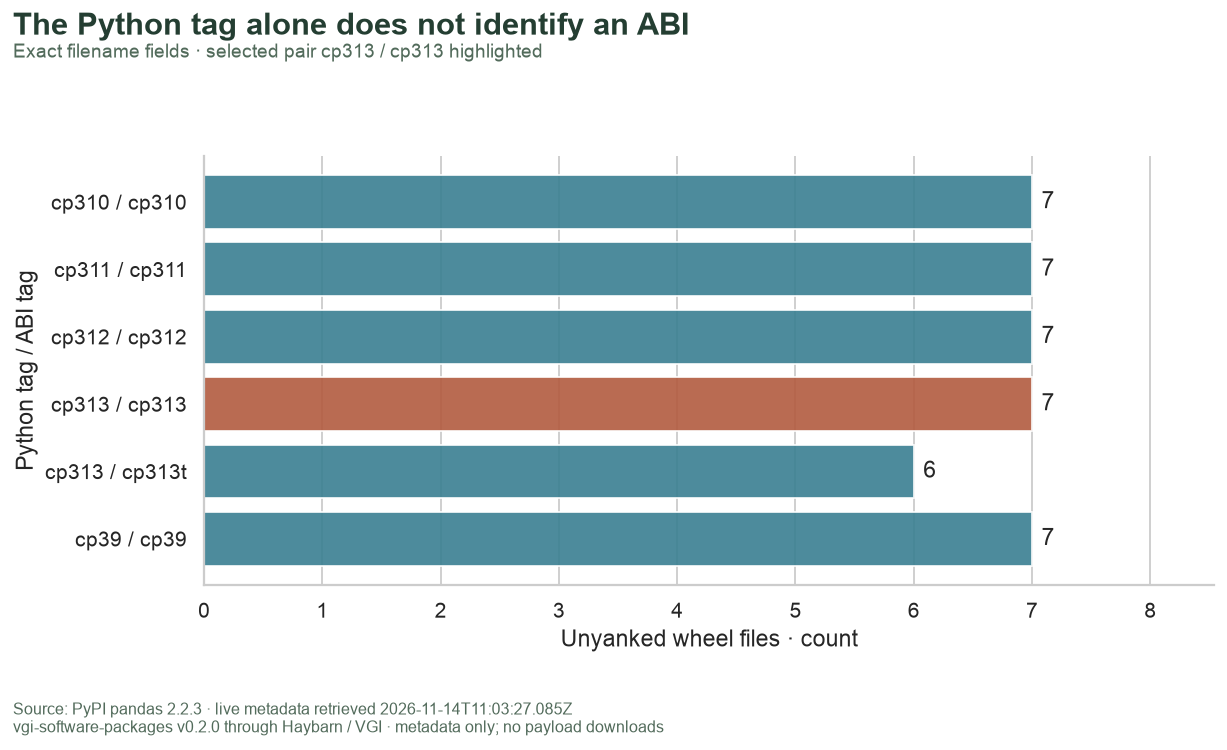

In [8]:
display(coverage)
source = f"Source: PyPI pandas 2.2.3 · live metadata retrieved {overview.iloc[0].first_observed_utc}"
fig, ax = plt.subplots(figsize=(10.5, 5.8))
labels = coverage.python_tag + " / " + coverage.abi_tag
colors = ["#b25b3f" if x else "#397f91" for x in coverage.selected]
ax.barh(labels, coverage.unyanked_files, color=colors, alpha=0.9)
for i, row in enumerate(coverage.itertuples()):
    ax.text(row.unyanked_files + 0.08, i, str(row.unyanked_files), va="center")
ax.invert_yaxis()
ax.set(
    xlabel="Unyanked wheel files · count",
    ylabel="Python tag / ABI tag",
    xlim=(0, float(coverage.unyanked_files.max()) * 1.22),
)
ax.grid(axis="y", visible=False)
finish(
    fig,
    f"wheel-coverage-{CPYTHON_TAG}",
    "The Python tag alone does not identify an ABI",
    f"Exact filename fields · selected pair {CPYTHON_TAG} / {CPYTHON_TAG} highlighted",
    source,
    left=0.22,
)

## Compare declared compressed file sizes

The candidate table requires the exact Python/ABI pair and `yanked=false`; missing size is never turned into zero. It retains the complete filename, platform aliases, Requires-Python declaration and SHA256 metadata. The chart shortens dotted platform aliases to their first component, but every full tag remains in the table.

**MiB = 2²⁰ bytes.** These are declared file download sizes, not installed footprints, memory use or performance. Hashes are registry metadata only: no artifact bytes are fetched to verify them. Selecting a platform still requires an installer’s compatibility rules and dependency resolution.

In [9]:
%%sql files <<
SELECT filename,python_tag,abi_tag,platform_tag,platform_label,size,size_mib,requires_python,sha256
FROM candidates ORDER BY size DESC,filename;

,filename,python_tag,abi_tag,platform_tag,platform_label,size,size_mib,requires_python,sha256
0,pandas-2.2.3-cp313-cp313-musllinux_1_2_aarch64...,cp313,cp313,musllinux_1_2_aarch64,musllinux_1_2_aarch64,16356316,15.598598,>=3.9,800250ecdadb6d9c78eae4990da62743b857b470883fa2...
1,pandas-2.2.3-cp313-cp313-manylinux2014_aarch64...,cp313,cp313,manylinux2014_aarch64.manylinux_2_17_aarch64,manylinux2014_aarch64,15196085,14.492116,>=3.9,22a9d949bfc9a502d320aa04e5d02feab689d61da4e776...
2,pandas-2.2.3-cp313-cp313-musllinux_1_2_x86_64.whl,cp313,cp313,musllinux_1_2_x86_64,musllinux_1_2_x86_64,14022055,13.372474,>=3.9,6374c452ff3ec675a8f46fd9ab25c4ad0ba590b71cf065...
3,pandas-2.2.3-cp313-cp313-manylinux_2_17_x86_64...,cp313,cp313,manylinux_2_17_x86_64.manylinux2014_x86_64,manylinux_2_17_x86_64,12711809,12.122926,>=3.9,f3a255b2c19987fbbe62a9dfd6cff7ff2aa9ccab3fc752...
4,pandas-2.2.3-cp313-cp313-macosx_10_13_x86_64.whl,cp313,cp313,macosx_10_13_x86_64,macosx_10_13_x86_64,12477643,11.899608,>=3.9,f00d1345d84d8c86a63e476bb4955e46458b304b9575dc...
5,pandas-2.2.3-cp313-cp313-win_amd64.whl,cp313,cp313,win_amd64,win_amd64,11481175,10.949302,>=3.9,61c5ad4043f791b61dd4752191d9f07f0ae412515d59ba...
6,pandas-2.2.3-cp313-cp313-macosx_11_0_arm64.whl,cp313,cp313,macosx_11_0_arm64,macosx_11_0_arm64,11281573,10.758946,>=3.9,3508d914817e153ad359d7e069d752cdd736a247c322d9...


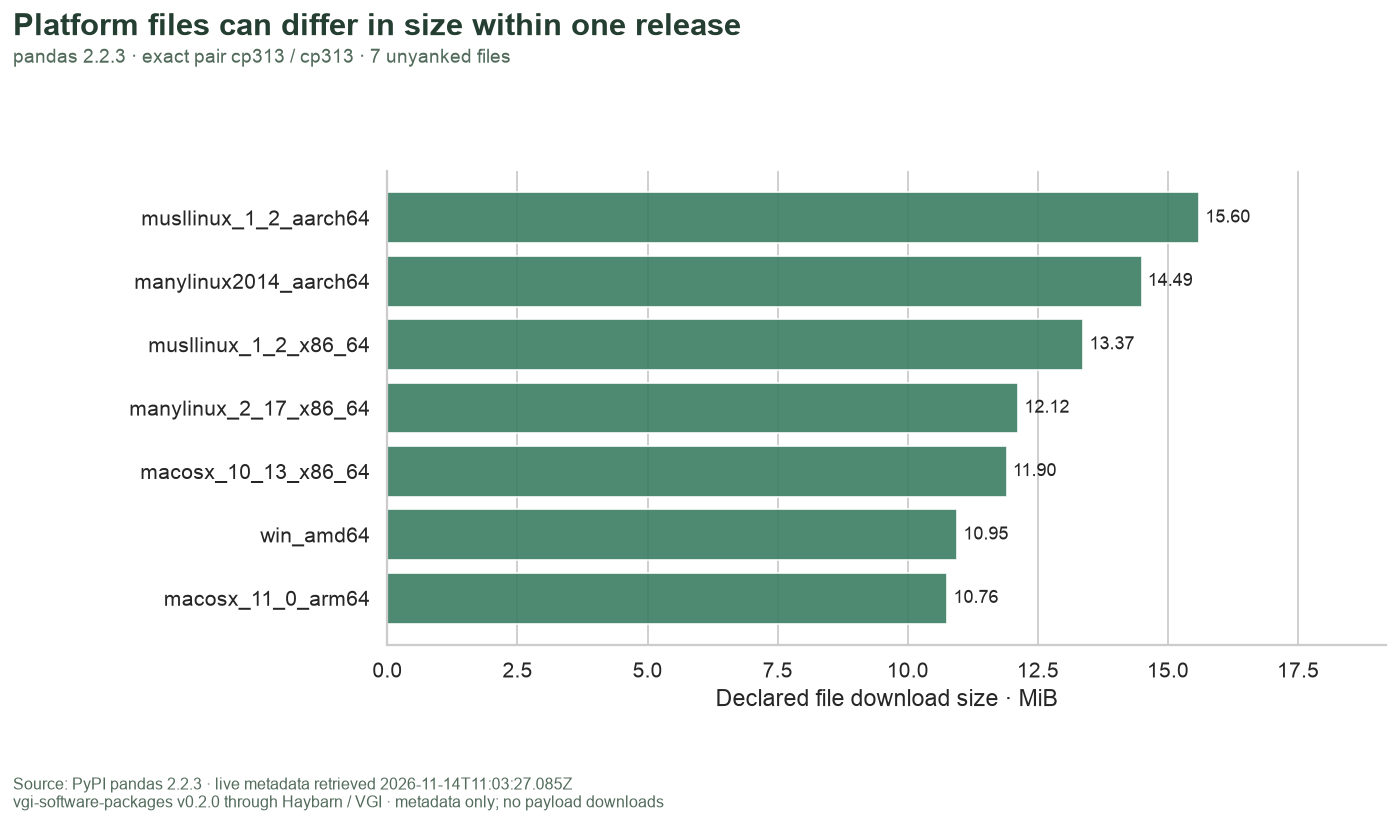

In [10]:
display(files)
assert len(files) > 0, "No unyanked wheels match this Python/ABI pair; inspect the inventory."
assert files["size"].notna().all(), "Selected wheels have unavailable sizes; inspect before plotting."
fig, ax = plt.subplots(figsize=(12, 6.4))
ax.barh(files.platform_label, files.size_mib, color="#397d62", alpha=0.9)
for i, row in enumerate(files.itertuples()):
    ax.text(row.size_mib + 0.12, i, f"{row.size_mib:.2f}", va="center", fontsize=10)
ax.invert_yaxis()
ax.set(xlabel="Declared file download size · MiB", xlim=(0, float(files.size_mib.max()) * 1.23))
ax.grid(axis="y", visible=False)
finish(
    fig,
    f"wheel-sizes-{CPYTHON_TAG}",
    "Platform files can differ in size within one release",
    f"pandas 2.2.3 · exact pair {CPYTHON_TAG} / {CPYTHON_TAG} · {len(files)} unyanked files",
    source,
    left=0.32,
)

In [11]:
largest = files.iloc[0]
smallest = files.iloc[-1]
info = overview.iloc[0]
display(
    Markdown(
        f"PyPI returned **{int(info.artifacts)} artifacts**, including **{int(info.wheels)} wheels** and "
        f"source archives (**{int(info.source_archives)}**). "
        f"The selected Python/ABI pair has **{len(files)}** unyanked files. "
        f"Their declared sizes range from **{smallest.size_mib:.2f} MiB** to **{largest.size_mib:.2f} MiB** "
        f"(**{largest.size_mib / smallest.size_mib:.2f}×**). The largest is `{largest.platform_tag}`. "
        "This difference alone cannot identify its cause or establish runtime performance."
    )
)

PyPI returned **42 artifacts**, including **41 wheels** and source archives (**1**). The selected Python/ABI pair has **7** unyanked files. Their declared sizes range from **10.76 MiB** to **15.60 MiB** (**1.45×**). The largest is `musllinux_1_2_aarch64`. This difference alone cannot identify its cause or establish runtime performance.

In [12]:
%%sql checks <<
SELECT 'bounded retrieval did not hit its row limit' AS check_name,(SELECT count(*)>0 AND count(*)<1000 FROM artifacts) AS passed
UNION ALL SELECT 'filenames identify unique artifacts',(SELECT count(*)=count(DISTINCT filename) FROM artifacts)
UNION ALL SELECT 'returned project and exact version agree',(SELECT bool_and(name='pandas' AND version='2.2.3') FROM artifacts)
UNION ALL SELECT 'every wheel has three parsed tag fields',(SELECT bool_and(python_tag<>'' AND abi_tag<>'' AND platform_tag<>'') FROM wheels)
UNION ALL SELECT 'selected pair matches both fields',(SELECT bool_and(python_tag='{{ CPYTHON_TAG }}' AND abi_tag='{{ CPYTHON_TAG }}') FROM candidates)
UNION ALL SELECT 'selected candidates are explicitly unyanked',(SELECT bool_and(yanked=false) FROM candidates)
UNION ALL SELECT 'selected sizes are positive and known',(SELECT count(*)=count(size) AND min(size)>0 FROM candidates)
UNION ALL SELECT 'MiB conversion reconciles with bytes',(SELECT bool_and(abs(size_mib*1048576-size)<0.5) FROM candidates)
UNION ALL SELECT 'selected SHA256 values are well formed',(SELECT bool_and(regexp_full_match(sha256,'[0-9a-f]{64}')) FROM candidates)
UNION ALL SELECT 'selected files are a subset of wheel inventory',NOT EXISTS(SELECT filename FROM candidates EXCEPT SELECT filename FROM wheels)
UNION ALL SELECT 'observation timestamps are present',(SELECT bool_and(try_cast(observed_at AS TIMESTAMPTZ) IS NOT NULL) FROM artifacts);

In [13]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks

,check_name,passed
0,bounded retrieval did not hit its row limit,True
1,filenames identify unique artifacts,True
2,returned project and exact version agree,True
3,every wheel has three parsed tag fields,True
4,selected pair matches both fields,True
5,selected candidates are explicitly unyanked,True
6,selected sizes are positive and known,True
7,MiB conversion reconciles with bytes,True
8,selected SHA256 values are well formed,True
9,selected files are a subset of wheel inventory,True


## Focused experiment: change the CPython pair

Change only **`CPYTHON_TAG` from cp313 to cp312**, restart and run all. Compare the highlighted inventory row, file count, platform labels and size range. Predict that changing a Python/ABI pair can change bytes without changing the project release. Neither direction of size change is guaranteed.

This performs another live metadata retrieval; compare observation timestamps and note any upstream changes before attributing differences to the parameter. It does not test installation or application compatibility. Restore **cp313** for the baseline; the README writes the experiment separately.

In [14]:
assert connection.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == []
connection.close()
notebook_secret_directory.cleanup()
public.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>